In [1]:
%load_ext autoreload
%autoreload 2

# Notebook 10: FINAL template vs NF samples vs simulation (component 01, DC4 511 keV binning)

- **Template:** expected counts per bin, from integrating the NF density (FINAL settings, all fixes, k = 2).
- **NF samples:** 97.5 M events drawn from the same NF model. Template vs samples tests the integral.
- **Simulation:** the simulated DC4 events of component 01. Template vs simulation tests the NF model.

**Residual** = (events − template) / √template: the difference in units of the Poisson noise.
If only noise, residuals have mean 0 and spread 1, and ~95% lie within ±2.

**χ²/dof** = mean of residual² over n values. The template is not fitted to the data, so noise alone gives 1 ± √(2/n).

Section 7 uses the Time axis of the simulation (the template and the NF samples have no time).

## Imports

In [2]:
import sys
from pathlib import Path
import numpy as np
import healpy as hp                            # sky maps and pixel positions
import astropy.units as u
from histpy import Histogram                   # template, samples and simulation histograms
from scoords import SpacecraftFrame            # registers the "spacecraftframe" frame, needed to open local histograms
from astropy.time import Time
from cosipy.spacecraftfile import SpacecraftHistory   # attitude and live time from the orientation file (Section 6)
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent.parent))     # project root, so `src` is importable
from src.plot_style import COLORS, set_global_style
set_global_style()

%matplotlib inline

## Configuration

In [3]:
# FINAL full-sky template (scripts/compute_full_sky_template.py): expected counts in the DC4 time window
FINAL_LOCAL_PATH = Path("../../data/NF_background/template/part-01_FINAL_k2_511keV_DC4binning_local.hdf5")

# NF samples of component 01, binned in the DC4 511 keV binning (notebook 08)
SAMPLES_LOCAL_PATH = Path("../../data/NF_background/samples/part-01_full_511keV_DC4binning_local.hdf5")

# Simulated DC4 events of component 01 (cosmic photons), same binning (notebook 08)
SIM_LOCAL_PATH = Path("../../data/background_components/CosmicPhotons_511keV_DC4binning_local.hdf5")

# Galactic frame (Section 7): template rotated with the attitude history; simulation binned with each event's own
# Galactic coordinates (notebook 08)
FINAL_GALACTIC_PATH = Path("../../data/NF_background/template/part-01_FINAL_k2_511keV_DC4binning_galactic.hdf5")
SIM_GALACTIC_PATH = Path("../../data/background_components/CosmicPhotons_511keV_DC4binning_galactic.hdf5")

# Orientation file: live time per time interval (Section 6)
ORI_PATH = Path("../../data/DC4_orientation.ori")

# PsiChi pixels of the binning
NSIDE, SCHEME = 16, "ring"                     # 3072 pixels, spacecraft frame

## Helper

In [4]:
def chi2_text(res):
    """
    Summarise residuals as chi2 per degree of freedom, and compare with pure Poisson noise.

    Input
    -----
    res : residuals r_i = (N_i - mu_i) / sqrt(mu_i), one per bin (any shape; flattened here)
          N_i  = observed counts in bin i (NF samples or simulation)
          mu_i = template (expected counts) in bin i

    Formulas
    --------
    chi2      = sum_i r_i^2                      (Pearson chi2)
    dof       = n                                (nothing in the template is fitted to these data)
    chi2/dof  = (1/n) * sum_i r_i^2              (= mean of r_i^2)
    noise     : if r_i ~ N(0, 1), then <r_i^2> = 1 and Var(r_i^2) = 2,
                so chi2/dof = 1 ± sqrt(2/n)
    """
    r = np.asarray(res).ravel()          # residuals r_i as a 1-D array
    n = r.size                           # number of bins = degrees of freedom

    chi2 = np.sum(r**2)                  # chi2 = sum_i r_i^2
    chi2_per_dof = chi2 / n              # chi2/dof
    noise_spread = np.sqrt(2 / n)        # expected spread of chi2/dof from Poisson noise alone

    return (f"chi2/dof {chi2_per_dof:.3f} "
            f"(noise only: 1 ± {noise_spread:.3f}, {n} values)")


***
## 1. Load and compare totals

In [5]:
# 1. Open the three histograms (axes, edges and units travel with the data)
template_local = Histogram.open(FINAL_LOCAL_PATH).to_dense()     # (Em, Phi, PsiChi)
samples_local  = Histogram.open(SAMPLES_LOCAL_PATH).to_dense()   # (Em, Phi, PsiChi)
sim_local      = Histogram.open(SIM_LOCAL_PATH)                  # (Time, Em, Phi, PsiChi), sparse; Time used in Section 7

# 2. Simulation summed over Time, so all three have the same axes
sim_local_tsum = sim_local.project("Em", "Phi", "PsiChi").to_dense()

# 3. Check that all three use the same binning (same axes, same edges)
print("samples    axes match template:", samples_local.axes == template_local.axes)
print("simulation axes match template:", sim_local_tsum.axes == template_local.axes)

# 4. Totals: (N_tot - mu_tot) / sqrt(mu_tot)
mu_tot = template_local.contents.sum()
for name, h in (("samples", samples_local), ("simulation", sim_local_tsum)):
    n_tot = h.contents.sum()
    print(f"{name:10s} {n_tot:9,.0f} vs template {mu_tot:9,.0f}: ratio {n_tot / mu_tot:.4f}, "
          f"difference {(n_tot - mu_tot) / np.sqrt(mu_tot):+.1f} sigma")


samples    axes match template: True
simulation axes match template: True
samples      161,582 vs template   162,625: ratio 0.9936, difference -2.6 sigma
simulation   162,652 vs template   162,625: ratio 1.0002, difference +0.1 sigma


In [ ]:
# Temporary: plain arrays for the cells not yet converted to Histogram style
N      = template_local.contents
n_samp = samples_local.contents
n_sim  = sim_local_tsum.contents
phi_edges = template_local.axes["Phi"].edges.to_value(u.deg)    # Phi bin edges [deg]

***
## 2. Sky: one residual per pixel

Sum over Em and Phi: one number per sky pixel.

In [7]:
# Sum over Em and Phi: one number per sky pixel, (3072,)
N_pix    = N.sum(axis=(0, 1))          # template mu_p
samp_pix = n_samp.sum(axis=(0, 1))     # NF samples N_p
sim_pix  = n_sim.sum(axis=(0, 1))      # simulation N_p

# Residual per pixel: r_p = (N_p - mu_p) / sqrt(mu_p)
res_pix = {"samples":    (samp_pix - N_pix) / np.sqrt(N_pix),
           "simulation": (sim_pix  - N_pix) / np.sqrt(N_pix)}

# Compare the 3072 residuals with pure noise, r_p ~ N(0, 1)
print("noise only: mean  0,     std 1,     |r| > 2 in 4.6% of pixels, chi2/dof 1 ± sqrt(2/n)")
for name, r in res_pix.items():
    print(f"{name:10s}: mean {r.mean():+.3f}, std {r.std():.3f}, |r| > 2 in {np.mean(np.abs(r) > 2):.1%} of pixels, "
          f"{chi2_text(r)}")


noise only: mean  0,     std 1,     |r| > 2 in 4.6% of pixels, chi2/dof 1 ± sqrt(2/n)
samples   : mean -0.046, std 1.008, |r| > 2 in 4.6% of pixels, chi2/dof 1.018 (noise only: 1 ± 0.026, 3072 values)
simulation: mean -0.021, std 1.434, |r| > 2 in 14.4% of pixels, chi2/dof 2.057 (noise only: 1 ± 0.026, 3072 values)



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



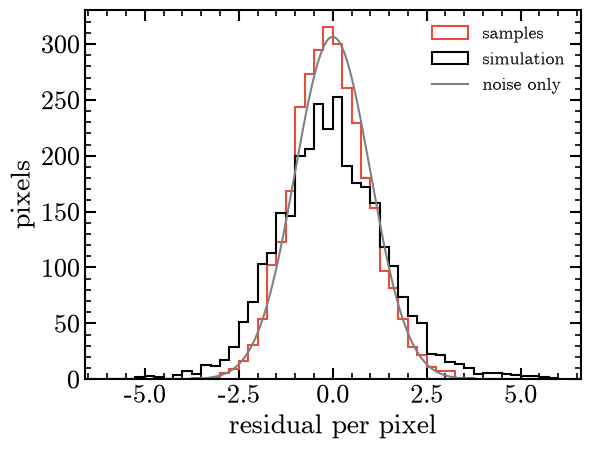

In [8]:
# Histogram of the residuals; grey: noise only (standard normal scaled to 3072 pixels)
bins = np.linspace(-6, 6, 49)
x = np.linspace(-6, 6, 400)
for name, color in (("samples", COLORS["nf_samples"]), ("simulation", COLORS["sim"])):
    plt.hist(res_pix[name], bins=bins, histtype="step", color=color, label=name)
    
plt.plot(x, len(N_pix) * np.diff(bins)[0] * np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color=COLORS["ref"], label="noise only")
plt.xlabel("residual per pixel"); plt.ylabel("pixels"); plt.legend();


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



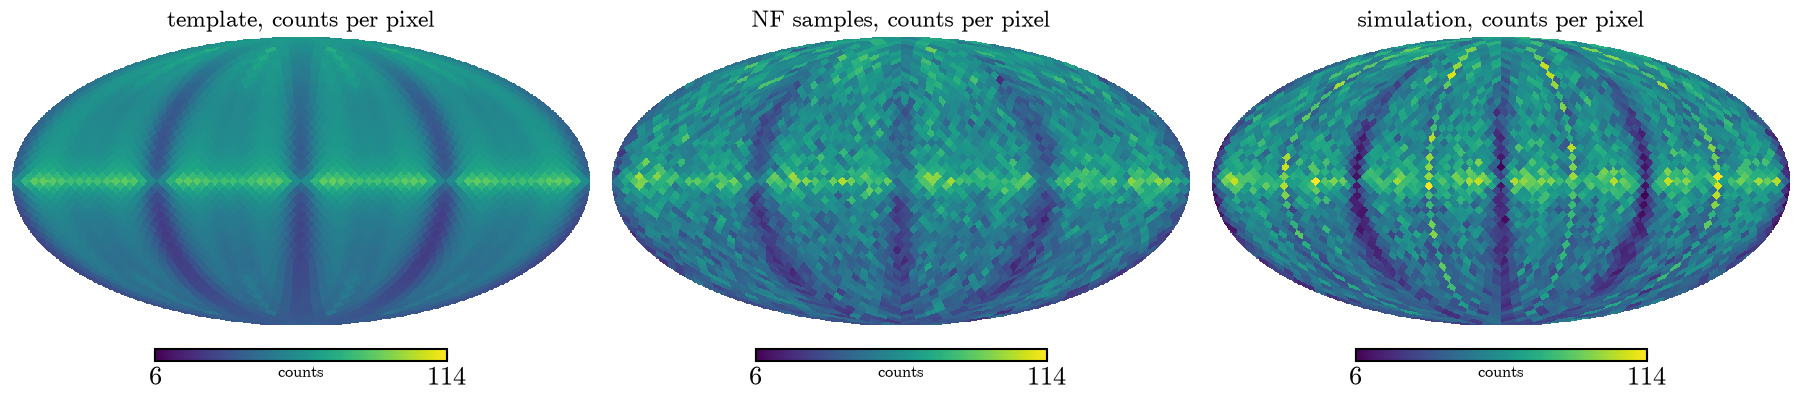

In [9]:
# Counts per PsiChi pixel (summed over Em and Phi): template, NF samples and simulation, same colour scale
maps = {"template":   template_local.project("PsiChi").contents,
        "NF samples": samples_local.project("PsiChi").contents,
        "simulation": sim_local_tsum.project("PsiChi").contents}

vmin, vmax = min(m.min() for m in maps.values()), max(m.max() for m in maps.values())
fig = plt.figure(figsize=(18, 4.5))
for k, (name, m) in enumerate(maps.items()):
    hp.mollview(m, fig=fig.number, sub=(1, 3, k + 1), min=vmin, max=vmax,
                unit="counts", title=f"{name}, counts per pixel")


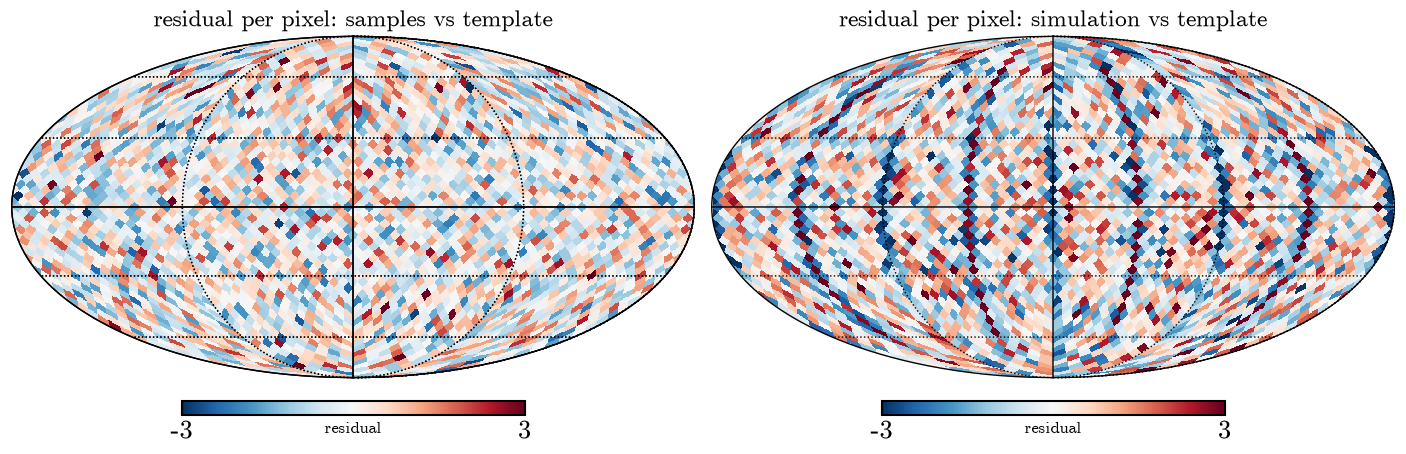

In [10]:
# Residual maps side by side (psi = 0 at the top, chi = 0 in the centre). Noise only: random red/blue, no bands or patches
fig = plt.figure(figsize=(14, 4.5))
for k, (name, r) in enumerate(res_pix.items()):
    hp.mollview(r, fig=fig.number, sub=(1, 2, k + 1), cmap="RdBu_r", min=-3, max=3,
                unit="residual", title=f"residual per pixel: {name} vs template")
    hp.graticule(dpar=30, dmer=90)       # grid: every 30 deg in psi, every 90 deg in chi



In [11]:
# Pixels crossed by the lines chi = 0, 90, 180, 270 deg, where 1.1% of simulated events sit exactly (simulation artefact)

psi_line = np.linspace(0, np.pi, 5000)                         # many points along each line, psi from 0 to 180 deg
line_pix = np.unique(np.concatenate([hp.ang2pix(NSIDE, psi_line, np.full_like(psi_line, np.deg2rad(chi)))
                                     for chi in (0, 90, 180, 270)]))
on_line = np.zeros(len(N_pix), bool)
on_line[line_pix] = True

# Residual statistics on and off those lines
for name, p in res_pix.items():
    for label, mask in (("on chi lines", on_line), ("off chi lines", ~on_line)):
        q = p[mask]
        print(f"{name:10s} {label:13s} {mask.sum():4d} pixels: mean {q.mean():+.3f}, std {q.std():.3f}, "
              f"|residual| > 2 in {np.mean(np.abs(q) > 2):.1%}, {chi2_text(q)}")

samples    on chi lines   192 pixels: mean -0.035, std 0.983, |residual| > 2 in 4.2%, chi2/dof 0.968 (noise only: 1 ± 0.102, 192 values)
samples    off chi lines 2880 pixels: mean -0.046, std 1.009, |residual| > 2 in 4.7%, chi2/dof 1.021 (noise only: 1 ± 0.026, 2880 values)
simulation on chi lines   192 pixels: mean -0.287, std 2.028, |residual| > 2 in 30.7%, chi2/dof 4.194 (noise only: 1 ± 0.102, 192 values)
simulation off chi lines 2880 pixels: mean -0.003, std 1.384, |residual| > 2 in 13.3%, chi2/dof 1.914 (noise only: 1 ± 0.026, 2880 values)


***
## 3. Phi: one residual per Phi bin

Sum over Em and all pixels: one number per 3° Phi bin.

samples    chi2/dof 0.827 (noise only: 1 ± 0.183, 60 values)
simulation chi2/dof 0.934 (noise only: 1 ± 0.183, 60 values)



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



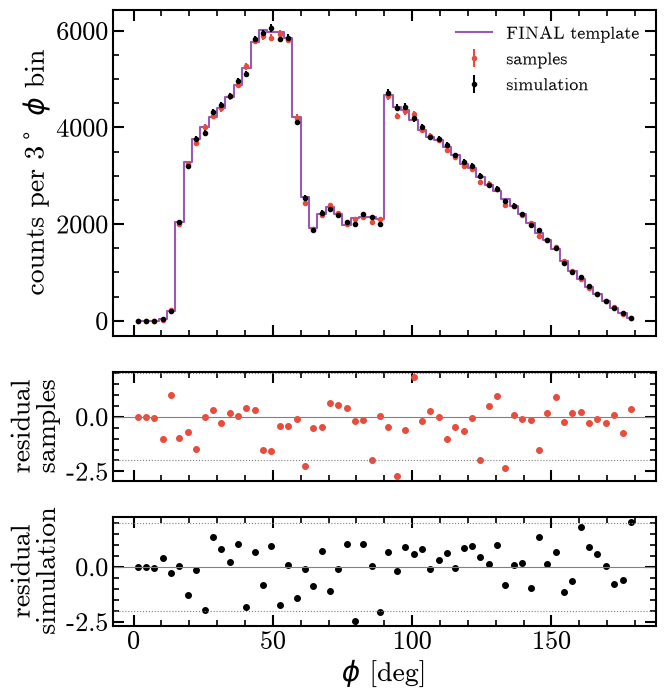

In [12]:
phi_centres = 0.5 * (phi_edges[:-1] + phi_edges[1:])
N_phi = N.sum(axis=(0, 2))
ok = N_phi > 0                                 # bins below ~10 deg are empty

fig, axs = plt.subplots(3, 1, sharex=True, height_ratios=[3, 1, 1], figsize=(7, 8))
axs[0].step(phi_centres, N_phi, where="mid", color=COLORS["nf"], label="FINAL template")
for a, (name, n, color) in zip(axs[1:], (("samples", n_samp, COLORS["nf_samples"]), ("simulation", n_sim, COLORS["sim"]))):
    
    n_phi = n.sum(axis=(0, 2))
    r = (n_phi[ok] - N_phi[ok]) / np.sqrt(N_phi[ok])
    print(f"{name:10s} {chi2_text(r)}")

    axs[0].errorbar(phi_centres, n_phi, yerr=np.sqrt(n_phi), fmt=".", color=color, label=name)
    a.plot(phi_centres[ok], r, "o", ms=4, color=color)

    for y, ls in ((0, "-"), (2, ":"), (-2, ":")):
        a.axhline(y, color=COLORS["ref"], ls=ls, lw=0.8)
    a.set_ylabel(f"residual\n{name}")
axs[0].set_ylabel(r"counts per 3$^\circ$ $\phi$ bin"); axs[0].legend()
axs[-1].set_xlabel(r"$\phi$ [deg]")
plt.show()

***
## 4. ψ: one residual per HEALPix ring

The pixels lie in 63 rings of equal ψ (4 to 64 pixels each). Upper panel: average counts per pixel of each ring;
residuals: ring totals.

In [13]:
psi_pix = np.rad2deg(hp.pix2ang(NSIDE, np.arange(len(N_pix)))[0])
ring_psi, ring_index = np.unique(psi_pix.round(6), return_inverse=True)    # 63 rings
n_pix_ring = np.bincount(ring_index)                                        # pixels per ring
N_ring = np.bincount(ring_index, weights=N_pix)                             # template, total per ring

samples    chi2/dof 1.150 (noise only: 1 ± 0.178, 63 values)
simulation chi2/dof 2.351 (noise only: 1 ± 0.178, 63 values)



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



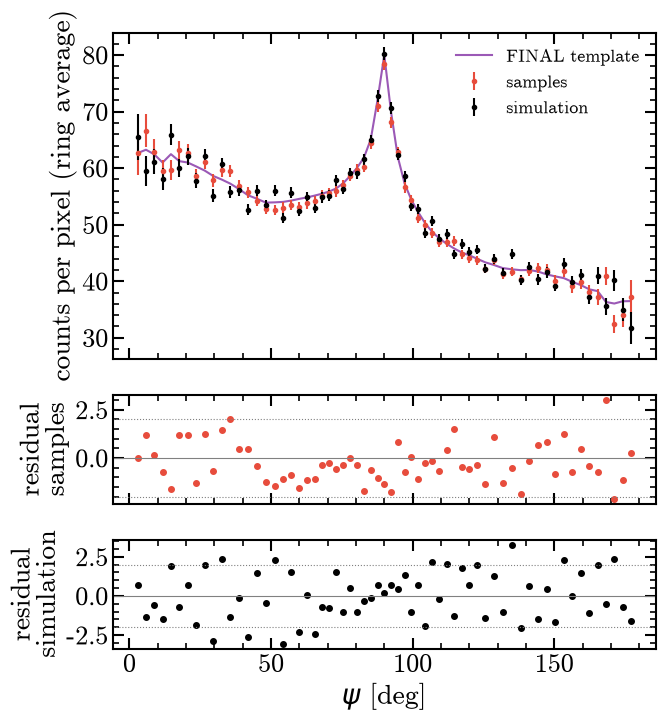

In [14]:
fig, axs = plt.subplots(3, 1, sharex=True, height_ratios=[3, 1, 1], figsize=(7, 8))
axs[0].plot(ring_psi, N_ring / n_pix_ring, "-", color=COLORS["nf"], label="FINAL template")

for a, (name, n, color) in zip(axs[1:], (("samples", n_samp, COLORS["nf_samples"]), ("simulation", n_sim, COLORS["sim"]))):
    n_ring = np.bincount(ring_index, weights=n.sum(axis=(0, 1)))
    r = (n_ring - N_ring) / np.sqrt(N_ring)
    print(f"{name:10s} {chi2_text(r)}")

    axs[0].errorbar(ring_psi, n_ring / n_pix_ring, yerr=np.sqrt(n_ring) / n_pix_ring, fmt=".", color=color, label=name)
    a.plot(ring_psi, r, "o", ms=4, color=color)

    for y, ls in ((0, "-"), (2, ":"), (-2, ":")):
        a.axhline(y, color=COLORS["ref"], ls=ls, lw=0.8)

    a.set_ylabel(f"residual\n{name}")
    
axs[0].set_ylabel("counts per pixel (ring average)"); axs[0].legend()
axs[-1].set_xlabel(r"$\psi$ [deg]")
plt.show()

***
## 5. Phi × ψ: one residual per (Phi bin, ψ ring)

The sky maps sum over Phi and the Phi profile sums over the sky; this keeps both. Each cell sums the pixels of one ψ ring.
Cells with fewer than 20 expected counts are blank.

In [15]:
def phi_ring(counts):
    """
    Regroup counts from (Em, Phi, PsiChi) into (Phi, psi ring).

    For each Phi bin and each psi ring, add up the counts of all pixels in that ring
    (all chi at that psi), after summing over energy:

        out[phi, ring] = sum over E, sum over pixels p in ring of counts[E, phi, p]

    Input:  counts, shape (Em, Phi, PsiChi) = (1, 60, 3072)
    Output: array,  shape (Phi, n_rings)    = (60, 63)
    Uses ring_index (ring number of each pixel) and ring_psi (psi of each ring) from Section 4.
    """
    counts_phi_pix = counts.sum(axis=0)                  # sum over energy → (Phi, PsiChi) = (60, 3072)
    n_phi, n_rings = counts_phi_pix.shape[0], len(ring_psi)

    out = np.zeros((n_phi, n_rings))
    for i_phi in range(n_phi):
        pixel_counts = counts_phi_pix[i_phi]             # counts of the 3072 pixels in this Phi bin
        out[i_phi] = np.bincount(ring_index,             # for each ring...
                                 weights=pixel_counts,   # ...add up the counts of its pixels
                                 minlength=n_rings)      # keep all 63 rings, even empty ones
    return out


In [16]:
N_pr = phi_ring(N)                                                                # template, (60, 63)
ok_pr = N_pr >= 10
psi_edges = np.concatenate([[0], 0.5 * (ring_psi[1:] + ring_psi[:-1]), [180]])   # ring boundaries [deg], for plotting


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



samples    chi2/dof 0.957 (noise only: 1 ± 0.027, 2685 values)
simulation chi2/dof 1.106 (noise only: 1 ± 0.027, 2685 values)


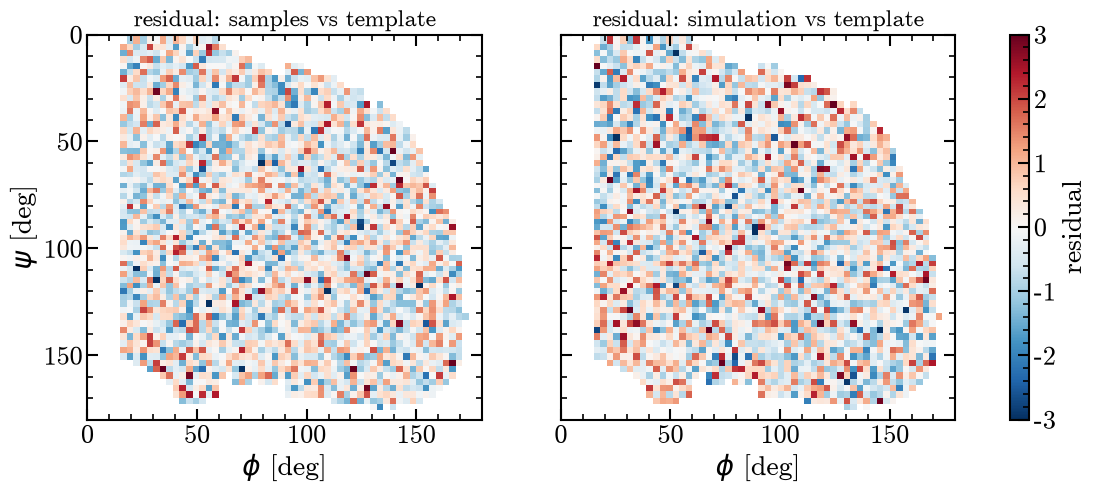

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for a, (name, n) in zip(axs, (("samples", n_samp), ("simulation", n_sim))):
    r = np.full(N_pr.shape, np.nan)
    r[ok_pr] = (phi_ring(n)[ok_pr] - N_pr[ok_pr]) / np.sqrt(N_pr[ok_pr])
    print(f"{name:10s} {chi2_text(r[ok_pr])}")
    im = a.pcolormesh(phi_edges, psi_edges, r.T, cmap="RdBu_r", vmin=-3, vmax=3)
    a.set_title(f"residual: {name} vs template"); a.set_xlabel(r"$\phi$ [deg]")
axs[0].set_ylabel(r"$\psi$ [deg]"); axs[0].invert_yaxis()                       # psi = 0 at the top, as in the maps
fig.colorbar(im, ax=axs, label="residual")
plt.show()

***
## 6. Time: simulation vs the time-independent template (local frame)

The template has no time. With a constant rate and shape, the expected counts in a time interval are
the template total × (live time in the interval / total live time).
Simulation: 2217 bins of 1 h; live time per bin from the orientation file. The NF samples have no times.

### 6.1 Rate: counts per hour and per day

live time per hour: 2,474 to 3,599 s; total 6,579,555 s
per hour: chi2/dof 1.029 (noise only: 1 ± 0.030, 2217 values)
per day:  chi2/dof 1.039 (noise only: 1 ± 0.147, 92 values)



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



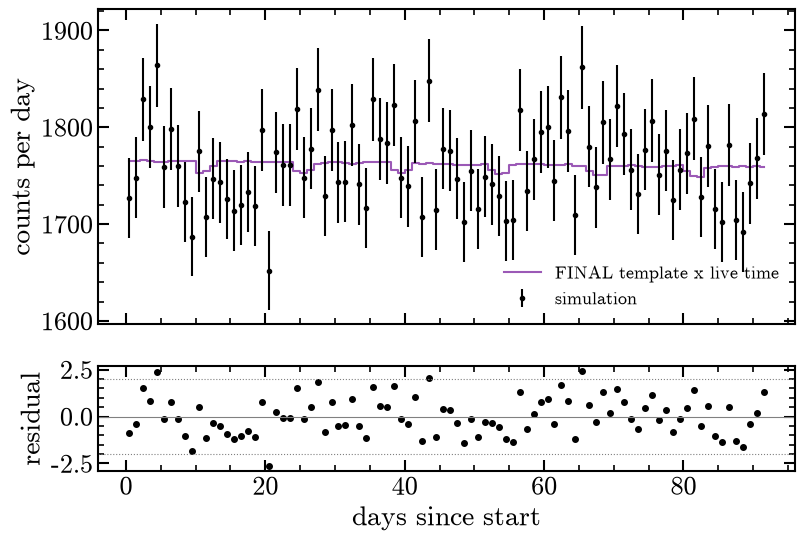

In [18]:
# Live time in each 1 h Time bin of the simulation
t_edges = sim_local.axes["Time"].edges.to_value(u.s)                              # unix time [s]
history = SpacecraftHistory.open(ORI_PATH).select_interval(Time(t_edges[0], format="unix"), Time(t_edges[-1], format="unix"))
livetime_t = np.diff(history.cumulative_livetime(Time(t_edges, format="unix")).to_value(u.s))   # [s] per bin
print(f"live time per hour: {livetime_t.min():,.0f} to {livetime_t.max():,.0f} s; total {livetime_t.sum():,.0f} s")

# Counts per hour: simulation, and template x live time fraction
n_t = np.asarray(sim_local.project("Time").to_dense().contents)
N_t = N.sum() * livetime_t / livetime_t.sum()
print(f"per hour: {chi2_text((n_t - N_t) / np.sqrt(N_t))}")

# Per day (24 hourly bins, full days only): less noise, shows slow trends
n_full = len(n_t) // 24 * 24                                                       # drop the last partial day
day = np.arange(n_full) // 24
n_day, N_day = np.bincount(day, weights=n_t[:n_full]), np.bincount(day, weights=N_t[:n_full])
days = np.bincount(day, weights=0.5 * (t_edges[:n_full] + t_edges[1:n_full + 1]) - t_edges[0]) / np.bincount(day) / 86400   # day centres
print(f"per day:  {chi2_text((n_day - N_day) / np.sqrt(N_day))}")

fig, axs = plt.subplots(2, 1, sharex=True, height_ratios=[3, 1], figsize=(9, 6))
axs[0].step(days, N_day, where="mid", color=COLORS["nf"], label="FINAL template x live time")
axs[0].errorbar(days, n_day, yerr=np.sqrt(n_day), fmt=".", color=COLORS["sim"], label="simulation")
axs[0].set_ylabel("counts per day"); axs[0].legend()
axs[1].plot(days, (n_day - N_day) / np.sqrt(N_day), "o", ms=4, color=COLORS["sim"])
for y, ls in ((0, "-"), (2, ":"), (-2, ":")):
    axs[1].axhline(y, color=COLORS["ref"], ls=ls, lw=0.8)
axs[1].set_xlabel("days since start"); axs[1].set_ylabel("residual")
plt.show()

### 6.2 Shape: four time slices

Each slice (~23 days) is compared with the template × (slice live time / total live time).

days  0.0-23.1: total ratio 0.9930; per pixel chi2/dof 1.233 (noise only: 1 ± 0.026, 3072 values); if the all-times excess only scales with counts: 1.265
days 23.1-46.2: total ratio 1.0063; per pixel chi2/dof 1.333 (noise only: 1 ± 0.026, 3072 values); if the all-times excess only scales with counts: 1.264
days 46.2-69.3: total ratio 1.0015; per pixel chi2/dof 1.178 (noise only: 1 ± 0.026, 3072 values); if the all-times excess only scales with counts: 1.264
days 69.3-92.4: total ratio 0.9999; per pixel chi2/dof 1.282 (noise only: 1 ± 0.026, 3072 values); if the all-times excess only scales with counts: 1.264



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



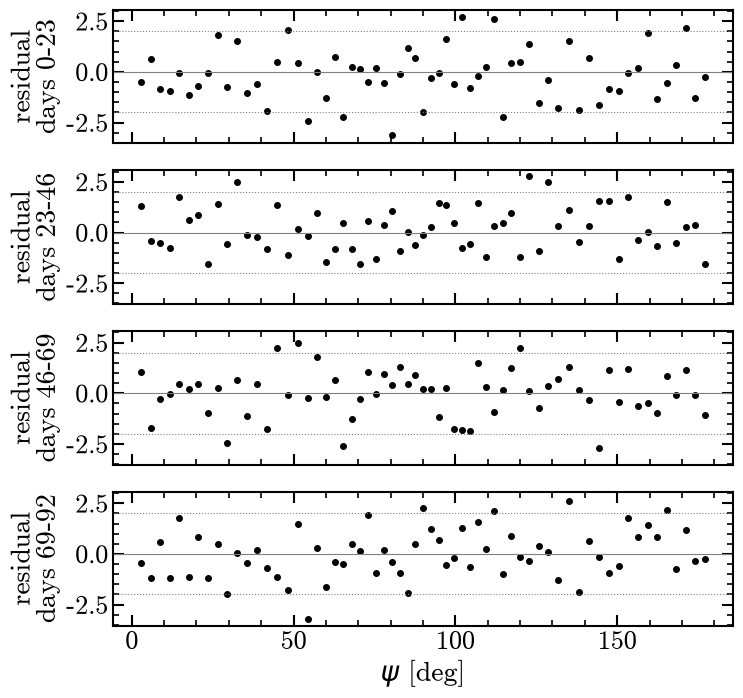

In [19]:
n_tpix = np.asarray(sim_local.project("Time", "PsiChi").to_dense().contents)     # simulation, (2217, 3072)
chi2_full = np.mean(res_pix["simulation"] ** 2)                                   # all times, Section 2

fig, axs = plt.subplots(4, 1, sharex=True, sharey=True, figsize=(8, 8))
for a, idx in zip(axs, np.array_split(np.arange(len(n_t)), 4)):
    frac = livetime_t[idx].sum() / livetime_t.sum()
    n_s, N_s = n_tpix[idx].sum(axis=0), N_pix * frac                              # per pixel, (3072,)
    d0, d1 = (t_edges[idx[0]] - t_edges[0]) / 86400, (t_edges[idx[-1] + 1] - t_edges[0]) / 86400
    print(f"days {d0:4.1f}-{d1:4.1f}: total ratio {n_s.sum() / N_s.sum():.4f}; per pixel {chi2_text((n_s - N_s) / np.sqrt(N_s))}; "
          f"if the all-times excess only scales with counts: {1 + (chi2_full - 1) * frac:.3f}")
    n_r, N_r = np.bincount(ring_index, weights=n_s), np.bincount(ring_index, weights=N_s)
    a.plot(ring_psi, (n_r - N_r) / np.sqrt(N_r), "o", ms=4, color=COLORS["sim"])
    for y, ls in ((0, "-"), (2, ":"), (-2, ":")):
        a.axhline(y, color=COLORS["ref"], ls=ls, lw=0.8)
    a.set_ylabel(f"residual\ndays {d0:.0f}-{d1:.0f}")
axs[-1].set_xlabel(r"$\psi$ [deg]")
plt.show()


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



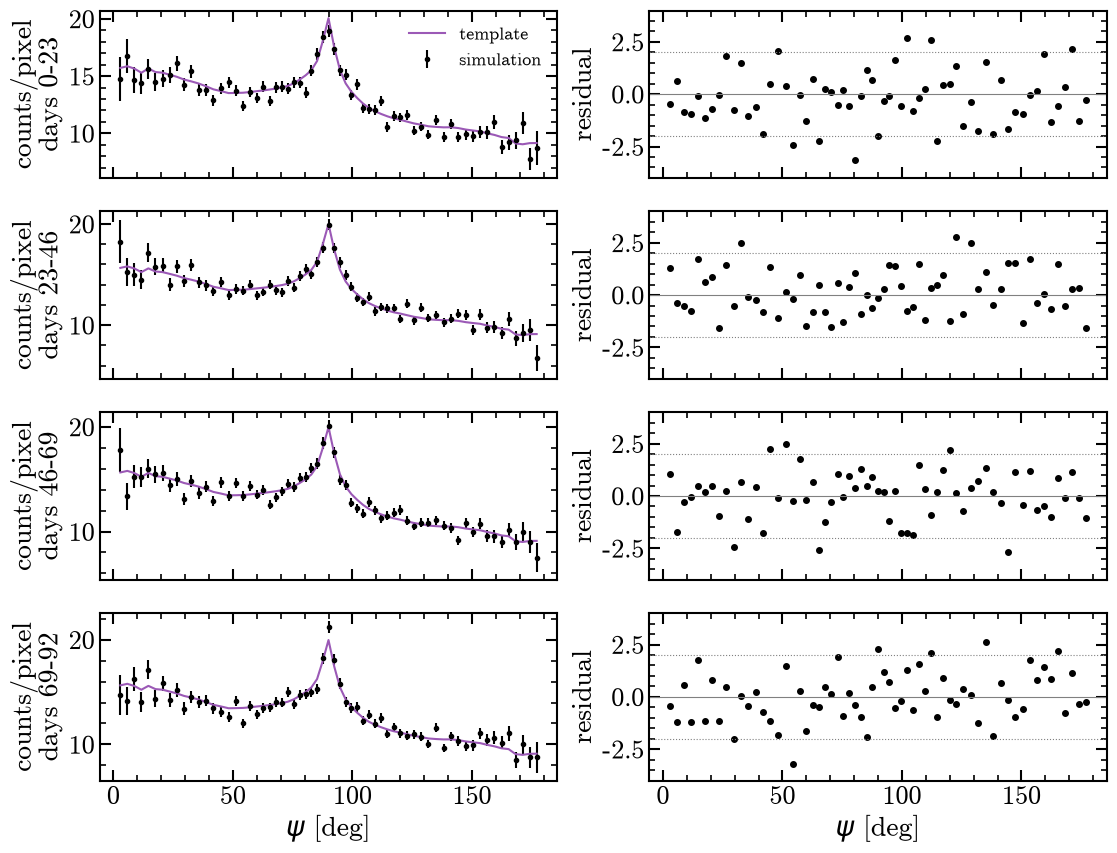

In [20]:
# psi per time slice: left = profile (simulation points, template line), right = residuals
fig, axs = plt.subplots(4, 2, sharex=True, figsize=(13, 10), width_ratios=[1, 1])
for (a_prof, a_res), idx in zip(axs, np.array_split(np.arange(len(n_t)), 4)):
    frac = livetime_t[idx].sum() / livetime_t.sum()                       # share of live time in this slice
    n_r = np.bincount(ring_index, weights=n_tpix[idx].sum(axis=0))        # simulation, total per ring
    N_r = np.bincount(ring_index, weights=N_pix * frac)                   # template, total per ring
    d0, d1 = (t_edges[idx[0]] - t_edges[0]) / 86400, (t_edges[idx[-1] + 1] - t_edges[0]) / 86400

    a_prof.errorbar(ring_psi, n_r / n_pix_ring, yerr=np.sqrt(n_r) / n_pix_ring, fmt=".", color=COLORS["sim"], label="simulation")
    a_prof.plot(ring_psi, N_r / n_pix_ring, "-", color=COLORS["nf"], label="template")
    a_prof.set_ylabel(f"counts/pixel\ndays {d0:.0f}-{d1:.0f}")

    a_res.plot(ring_psi, (n_r - N_r) / np.sqrt(N_r), "o", ms=4, color=COLORS["sim"])
    for y, ls in ((0, "-"), (2, ":"), (-2, ":")):
        a_res.axhline(y, color=COLORS["ref"], ls=ls, lw=0.8)
    a_res.set_ylim(-4, 4); a_res.set_ylabel("residual")
axs[0, 0].legend()
axs[-1, 0].set_xlabel(r"$\psi$ [deg]"); axs[-1, 1].set_xlabel(r"$\psi$ [deg]")
plt.show()


***
## 7. Galactic frame: template vs simulation

- Template: the local template rotated to Galactic coordinates with the attitude history (live-time weighted).
- Simulation: each event binned with its own Galactic coordinates, so its counts are Poisson.
- NF samples are left out here: their Galactic histogram is the local one rotated with the same method as the
  template, so it adds nothing to Sections 1–5 and its counts are no longer Poisson.

In [21]:
N_gal = np.asarray(Histogram.open(FINAL_GALACTIC_PATH).to_dense().contents)                                  # template
n_sim_gal = np.asarray(Histogram.open(SIM_GALACTIC_PATH).project("Em", "Phi", "PsiChi").to_dense().contents)   # simulation
print(f"shapes: template {N_gal.shape}, simulation {n_sim_gal.shape}")
print(f"total: simulation {n_sim_gal.sum():,.0f} vs template {N_gal.sum():,.0f}: ratio {n_sim_gal.sum() / N_gal.sum():.4f}")

# One residual per Galactic pixel (sum over Em and Phi)
N_gal_pix = N_gal.sum(axis=(0, 1))
n_sim_gal_pix = n_sim_gal.sum(axis=(0, 1))
res_gal = (n_sim_gal_pix - N_gal_pix) / np.sqrt(N_gal_pix)
print(f"residuals: mean {res_gal.mean():+.3f}, std {res_gal.std():.3f}, |residual| > 2 in {np.mean(np.abs(res_gal) > 2):.1%} of pixels")
print(f"residuals: {chi2_text(res_gal)}")
print("noise only: mean 0, std 1, |residual| > 2 in 4.6% of pixels")

shapes: template (1, 60, 3072), simulation (1, 60, 3072)
total: simulation 162,652 vs template 162,632: ratio 1.0001
residuals: mean -0.002, std 1.011, |residual| > 2 in 5.0% of pixels
residuals: chi2/dof 1.022 (noise only: 1 ± 0.026, 3072 values)
noise only: mean 0, std 1, |residual| > 2 in 4.6% of pixels



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



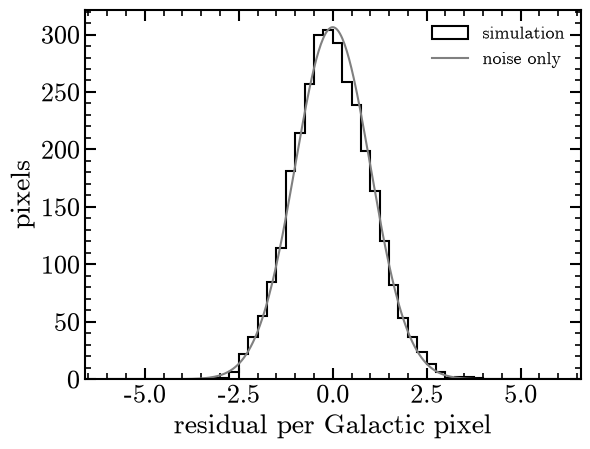

In [22]:
# Histogram of the Galactic residuals; grey: noise only
plt.hist(res_gal, bins=bins, histtype="step", color=COLORS["sim"], label="simulation")
plt.plot(x, len(res_gal) * np.diff(bins)[0] * np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color=COLORS["ref"], label="noise only")
plt.xlabel("residual per Galactic pixel"); plt.ylabel("pixels"); plt.legend(); plt.show()


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



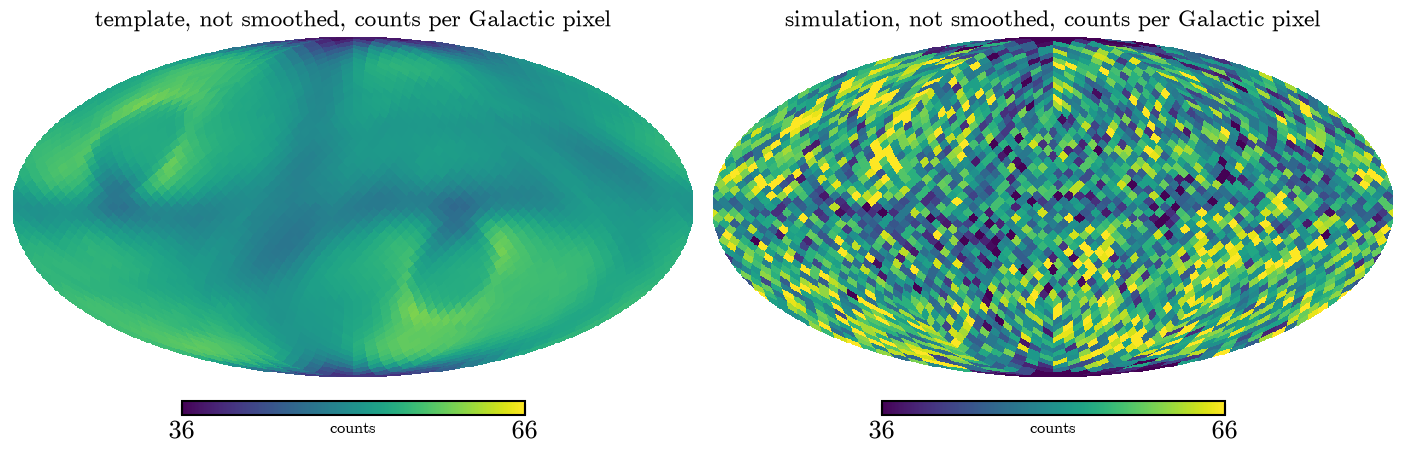

In [23]:
# Counts per Galactic pixel (Galactic centre in the middle): template vs simulation, not smoothed; same colour scale
maps_gal_raw = {"template": N_gal_pix, "simulation": n_sim_gal_pix}
# colour limits: 2nd and 95th percentiles of the simulation, so a few extreme noisy pixels don't stretch the scale
vmin, vmax = np.percentile(n_sim_gal_pix, [2, 95])
fig = plt.figure(figsize=(14, 4.5))
for k, (name, m) in enumerate(maps_gal_raw.items()):
    hp.mollview(m, nest=(SCHEME == "nested"), fig=fig.number, sub=(1, 2, k + 1), min=vmin, max=vmax,
                unit="counts", title=f"{name}, not smoothed, counts per Galactic pixel")


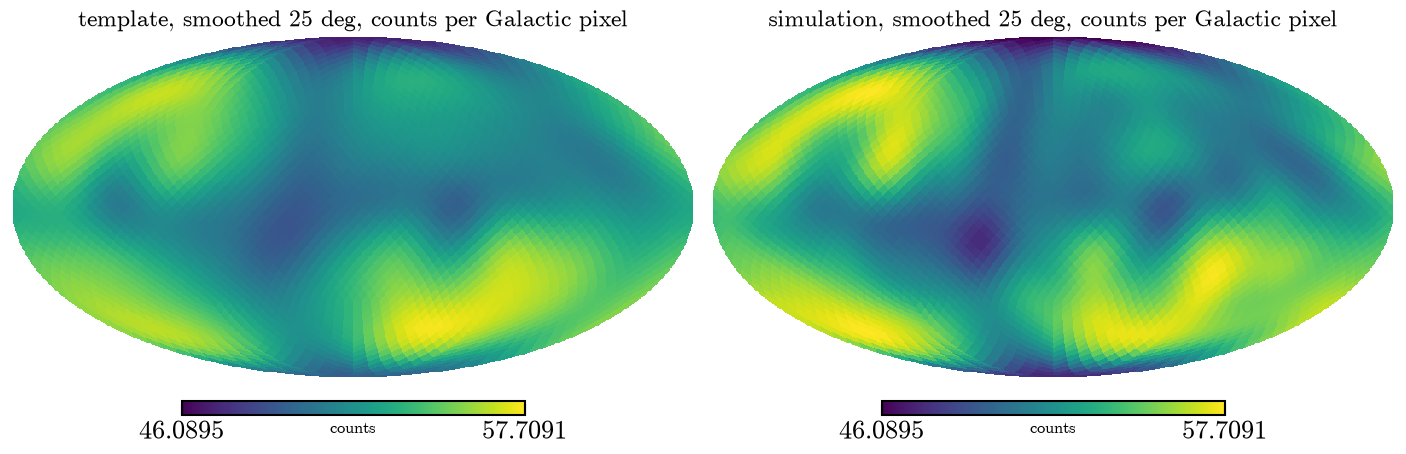

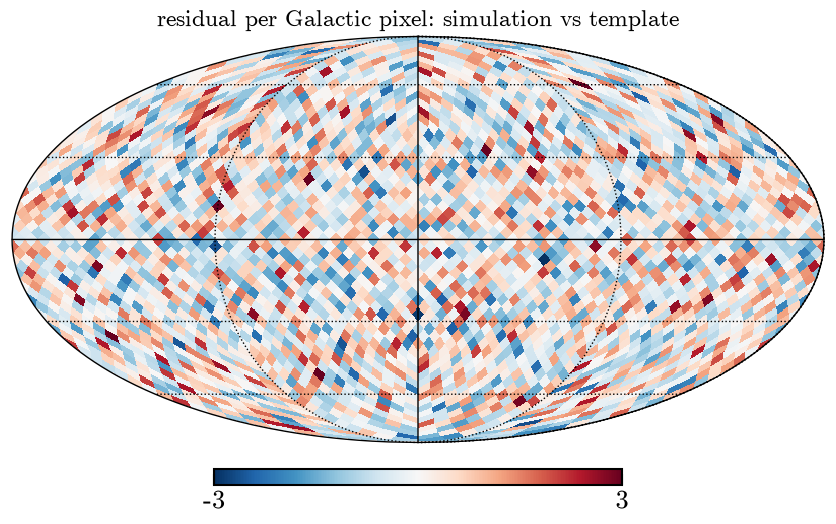

In [24]:
# Counts per Galactic pixel (Galactic centre in the middle). Both maps are smoothed the same way
# (each pixel averaged with its neighbours, Gaussian of FWHM_DEG), so only the noise differs between them.
# The unsmoothed simulation is compared pixel by pixel in the residual map below.
FWHM_DEG = 25.0

def smooth(m):
    """Gaussian smoothing of a HEALPix map; healpy smoothing works in RING ordering."""
    m_ring = m if SCHEME == "ring" else hp.reorder(m, n2r=True)
    m_smooth = hp.smoothing(m_ring, fwhm=np.deg2rad(FWHM_DEG))
    return m_smooth if SCHEME == "ring" else hp.reorder(m_smooth, r2n=True)

maps_gal = {"template": smooth(N_gal_pix), "simulation": smooth(n_sim_gal_pix)}
vmin, vmax = min(m.min() for m in maps_gal.values()), max(m.max() for m in maps_gal.values())
fig = plt.figure(figsize=(14, 4.5))
for k, (name, m) in enumerate(maps_gal.items()):
    hp.mollview(m, fig=fig.number, sub=(1, 2, k + 1), min=vmin, max=vmax,
                unit="counts", title=f"{name}, smoothed {FWHM_DEG:.0f} deg, counts per Galactic pixel")
plt.show()

hp.mollview(res_gal, cmap="RdBu_r", min=-3, max=3, title="residual per Galactic pixel: simulation vs template")
hp.graticule(dpar=30, dmer=90)
plt.show()


Galactic latitude profile: one point per HEALPix ring (rings are lines of constant latitude b).

latitude rings: chi2/dof 1.021 (noise only: 1 ± 0.178, 63 values)



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



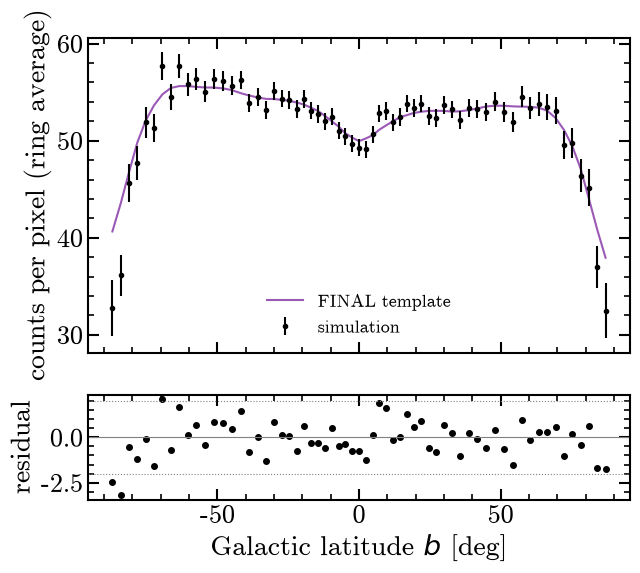

In [25]:
b_pix = 90 - np.rad2deg(hp.pix2ang(NSIDE, np.arange(len(N_gal_pix)))[0])   # latitude [deg]
ring_b, ring_index_gal = np.unique(b_pix.round(6), return_inverse=True)
n_pix_ring_gal = np.bincount(ring_index_gal)
N_ring_gal = np.bincount(ring_index_gal, weights=N_gal_pix)
n_ring_gal = np.bincount(ring_index_gal, weights=n_sim_gal_pix)

fig, (ax, ax_res) = plt.subplots(2, 1, sharex=True, height_ratios=[3, 1], figsize=(7, 6))
ax.plot(ring_b, N_ring_gal / n_pix_ring_gal, "-", color=COLORS["nf"], label="FINAL template")
ax.errorbar(ring_b, n_ring_gal / n_pix_ring_gal, yerr=np.sqrt(n_ring_gal) / n_pix_ring_gal, fmt=".",
            color=COLORS["sim"], label="simulation")
ax.set_ylabel("counts per pixel (ring average)"); ax.legend()
r = (n_ring_gal - N_ring_gal) / np.sqrt(N_ring_gal)
print(f"latitude rings: {chi2_text(r)}")
ax_res.plot(ring_b, r, "o", ms=4, color=COLORS["sim"])
for y, ls in ((0, "-"), (2, ":"), (-2, ":")):
    ax_res.axhline(y, color=COLORS["ref"], ls=ls, lw=0.8)
ax_res.set_xlabel("Galactic latitude $b$ [deg]"); ax_res.set_ylabel("residual")
plt.show()